In [ ]:
"""Funciones de apoyo para bosques aleatorios, boosting e interpretación global
de modelos de caja negra (segundo taller de árboles e interpretabilidad).

Uso, con este archivo en la carpeta de trabajo:

    from functions_p2 import (error_por_arboles, error_oob, comparar_modelos,
                              curva_parametro, tabla_importancia,
                              graficar_importancia, importancia_sin_variable,
                              agregar_ruido, graficar_dependencia_parcial,
                              graficar_ice_por_grupo, evaluar_sustituto)

Los modelos se ajustan con scikit-learn (RandomForestRegressor,
GradientBoostingClassifier, ...) y se pasan a estas funciones. Sirven para
regresión y para clasificación: en regresión el error es el MSE y en
clasificación la tasa de error. Los datos deben ser DataFrame y Series de pandas.

    error_por_arboles             error de prueba con los B primeros árboles
    error_oob                     error out-of-bag de un bosque o bagging
    comparar_modelos              ajusta varios modelos y compara su error de prueba
    curva_parametro               error de entrenamiento y de prueba según un parámetro
    tabla_importancia             importancia por impureza y por permutación
    graficar_importancia          gráfico de barras de la importancia
    importancia_sin_variable      importancia por permutación con y sin una predictora
    agregar_ruido                 agrega una predictora binaria y otra continua de ruido
    graficar_dependencia_parcial  dependencia parcial y curvas ICE
    graficar_ice_por_grupo        curvas ICE centradas, coloreadas según un grupo
    evaluar_sustituto             fidelidad, error y reglas de un árbol sustituto
"""
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone, is_classifier
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score
from sklearn.model_selection import PredefinedSplit, validation_curve
from sklearn.tree import export_text
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import (GridSearchCV, PredefinedSplit, train_test_split, validation_curve)


from ISLP import load_data

SEMILLA = 2026


# ---------------------------------------------------------------------
#                         Funciones auxiliares
# ---------------------------------------------------------------------
def _nombre_error(modelo):
    return "Tasa de error" if is_classifier(modelo) else "MSE"


def _error(modelo, y, pred):
    # MSE en regresión y tasa de error en clasificación.
    if is_classifier(modelo):
        return 1 - accuracy_score(y, pred)
    return mean_squared_error(y, pred)


def _metrica(modelo):
    # Métrica equivalente de scikit-learn (mayor es mejor).
    return "accuracy" if is_classifier(modelo) else "neg_mean_squared_error"


def _a_error(modelo, puntaje):
    # Convierte el puntaje de _metrica en error.
    return 1 - puntaje if is_classifier(modelo) else -puntaje


def _proba_arbol(arbol, X, n_clases):
    # Probabilidades de un árbol con una columna por clase del ensamble, aunque a
    # su muestra le falte alguna clase (las clases vienen codificadas 0, ..., k - 1).
    prob = np.zeros((len(X), n_clases))
    prob[:, arbol.classes_.astype(int)] = arbol.predict_proba(X)
    return prob


def _error_acumulado(modelo, X, y):
    # Boosting: staged_predict da la predicción tras cada árbol.
    if hasattr(modelo, "staged_predict"):
        return pd.Series([_error(modelo, y, pred) for pred in modelo.staged_predict(X)])
    # Bagging y bosques: el modelo con B árboles promedia los B primeros.
    X = np.asarray(X, dtype=float)
    arboles = modelo.estimators_
    columnas = getattr(modelo, "estimators_features_", [slice(None)] * len(arboles))
    if is_classifier(modelo):
        k = len(modelo.classes_)
        prob = np.array([_proba_arbol(a, X[:, c], k) for a, c in zip(arboles, columnas)])
        prob = prob.cumsum(axis=0) / np.arange(1, len(arboles) + 1)[:, None, None]
        return pd.Series([_error(modelo, y, modelo.classes_[p.argmax(axis=1)])
                          for p in prob])
    pred = pd.DataFrame([a.predict(X[:, c]) for a, c in zip(arboles, columnas)])
    return pred.expanding().mean().sub(np.asarray(y)).pow(2).mean(axis=1)


def _a_flotante(X, variables):
    # La dependencia parcial no admite columnas enteras: se pasan a float.
    nombres = [v for item in variables
               for v in (item if isinstance(item, tuple) else (item,))]
    return X.astype({v: float for v in nombres if pd.api.types.is_integer_dtype(X[v])})


# ---------------------------------------------------------------------
#                    Bosques aleatorios y boosting
# ---------------------------------------------------------------------
def error_por_arboles(modelos, X_prueba, y_prueba):
    """Error de prueba de cada modelo usando solo sus B primeros árboles.

    modelos: un modelo ajustado o un diccionario {nombre: modelo ajustado} de
    bosques aleatorios, bagging o boosting. No hace falta reajustar: en bagging
    y bosques el modelo con B árboles es el promedio de los B primeros, y en
    boosting se usa staged_predict.
    Devuelve un DataFrame (filas: B = 1, 2, ...; columnas: modelos) y grafica
    una curva por modelo.
    """
    if not isinstance(modelos, dict):
        modelos = {"modelo": modelos}
    curvas = pd.DataFrame({nombre: _error_acumulado(m, X_prueba, y_prueba)
                           for nombre, m in modelos.items()})
    curvas.index = curvas.index + 1
    ax = curvas.plot(xlabel="Número de árboles B",
                     ylabel=_nombre_error(next(iter(modelos.values()))) + " de prueba")
    if len(curvas) > 20:  # se recorta el error de los primeros árboles, que es mayor
        resto = curvas.iloc[9:]
        margen = 0.05 * (resto.max().max() - resto.min().min())
        ax.set_ylim(resto.min().min() - margen, resto.max().max() + margen)
    ax.legend(ncol=min(len(modelos), 5), loc="lower center", bbox_to_anchor=(0.5, 1))
    plt.show()
    return curvas


def error_oob(bosque, y_entrenamiento):
    """Error out-of-bag de un bosque aleatorio o bagging ajustado con oob_score=True.

    Cada observación de entrenamiento se predice solo con los árboles que no la
    usaron, así que estima el error de prueba sin separar datos.
    """
    if is_classifier(bosque):
        pred = bosque.classes_[np.argmax(bosque.oob_decision_function_, axis=1)]
    else:
        pred = bosque.oob_prediction_
    return _error(bosque, y_entrenamiento, pred)


def comparar_modelos(modelos, X_ent, y_ent, X_pru, y_pru):
    """Ajusta cada modelo del diccionario {nombre: modelo} con el entrenamiento y
    compara su error de prueba (MSE y R2 en regresión; tasa de error en
    clasificación). Los modelos quedan ajustados.
    """
    filas = {}
    for nombre, modelo in modelos.items():
        pred = modelo.fit(X_ent, y_ent).predict(X_pru)
        filas[nombre] = {_nombre_error(modelo): _error(modelo, y_pru, pred)}
        if not is_classifier(modelo):
            filas[nombre]["R2"] = r2_score(y_pru, pred)
    return pd.DataFrame(filas).T


def curva_parametro(modelo, X_ent, y_ent, X_pru, y_pru, parametro, valores,
                    logx=False):
    """Error de entrenamiento y de prueba del modelo para cada valor de un parámetro.

    parametro: nombre del parámetro de scikit-learn, por ejemplo "learning_rate"
    (lambda en boosting), "n_estimators" (B), "max_leaf_nodes" (d + 1) o
    "max_features" (m en un bosque). El modelo se reajusta para cada valor.
    Devuelve un DataFrame (filas: valores) y grafica las dos curvas; la línea
    vertical marca el valor con menor error de prueba.
    """
    X = pd.concat([X_ent, X_pru])
    y = pd.concat([y_ent, y_pru])
    # -1: siempre en entrenamiento; 0: conjunto de prueba
    particion = PredefinedSplit(np.r_[np.full(len(y_ent), -1), np.zeros(len(y_pru))])
    ent, pru = validation_curve(modelo, X, y, param_name=parametro,
                                param_range=valores, cv=particion,
                                scoring=_metrica(modelo))
    curvas = pd.DataFrame({"entrenamiento": _a_error(modelo, ent[:, 0]),
                           "prueba": _a_error(modelo, pru[:, 0])}, index=valores)
    curvas.index.name = parametro
    ax = curvas.plot(logx=logx, marker="o", ylabel=_nombre_error(modelo))
    ax.axvline(curvas["prueba"].idxmin(), color="gray", linestyle="--")
    plt.show()
    return curvas


# ---------------------------------------------------------------------
#                      Importancia de las variables
# ---------------------------------------------------------------------
def tabla_importancia(modelo, X_prueba, y_prueba, n_repeticiones=5,
                      semilla=SEMILLA):
    """Importancia de cada predictora de un modelo ajustado.

    impureza: proporción de la reducción total de impureza (RSS o Gini) lograda
        en el entrenamiento con cortes en la variable. Solo modelos de árboles;
        favorece a las variables con muchos puntos de corte.
    permutacion: aumento promedio del error de prueba (MSE o tasa de error) al
        permutar la variable, con su desviación estándar entre repeticiones.
    Ordenada de mayor a menor importancia por permutación.
    """
    perm = permutation_importance(modelo, X_prueba, y_prueba,
                                  scoring=_metrica(modelo),
                                  n_repeats=n_repeticiones, random_state=semilla)
    tabla = pd.DataFrame({"permutacion": perm.importances_mean,
                          "desv_permutacion": perm.importances_std},
                         index=X_prueba.columns)
    if hasattr(modelo, "feature_importances_"):
        tabla.insert(0, "impureza", modelo.feature_importances_)
    return tabla.sort_values("permutacion", ascending=False)


def graficar_importancia(tabla, columna="permutacion"):
    """Gráfico de barras horizontales de una columna de tabla_importancia
    ("permutacion", con barras de error, o "impureza")."""
    tabla = tabla.sort_values(columna)
    error = tabla["desv_permutacion"] if columna == "permutacion" else None
    ax = tabla[columna].plot.barh(xerr=error)
    ax.set_xlabel("Aumento del error al permutar" if columna == "permutacion"
                  else "Reducción de impureza (proporción)")
    plt.show()


def importancia_sin_variable(modelo, X_ent, y_ent, X_pru, y_pru, variable,
                             semilla=SEMILLA):
    """Importancia por permutación con todas las predictoras y sin `variable`.

    Reajusta el modelo (sin ajustar) con y sin la variable, imprime el error de
    prueba de ambos y devuelve una tabla con las dos importancias. Sirve para
    ver cómo una predictora muy correlacionada se reparte la importancia con otra.
    """
    completo = clone(modelo).fit(X_ent, y_ent)
    reducido = clone(modelo).fit(X_ent.drop(columns=variable), y_ent)
    for nombre, m, X in [("con", completo, X_pru),
                         ("sin", reducido, X_pru.drop(columns=variable))]:
        print(f"{_nombre_error(m)} de prueba {nombre} {variable}:",
              _error(m, y_pru, m.predict(X)))
    tabla = pd.DataFrame({
        f"con_{variable}": tabla_importancia(completo, X_pru, y_pru,
                                             semilla=semilla)["permutacion"],
        f"sin_{variable}": tabla_importancia(reducido, X_pru.drop(columns=variable),
                                             y_pru, semilla=semilla)["permutacion"]})
    return tabla.sort_values(f"con_{variable}", ascending=False)


def agregar_ruido(X, semilla=SEMILLA):
    """Agrega a X dos predictoras sin relación con la respuesta:
    ruido_bin ~ Bernoulli(0.5) y ruido_cont ~ N(0, 1)."""
    rng = np.random.default_rng(semilla)
    return X.assign(ruido_bin=rng.binomial(1, 0.5, len(X)),
                    ruido_cont=rng.normal(size=len(X)))


# ---------------------------------------------------------------------
#               Dependencia parcial, curvas ICE y sustitutos
# ---------------------------------------------------------------------
def graficar_dependencia_parcial(modelo, X, variables, ice=False, centrado=False,
                                 n_ice=50, semilla=SEMILLA):
    """Dependencia parcial de cada variable de la lista `variables`: promedio de
    las predicciones sobre X al fijar la variable en cada valor de una grilla.

    ice=True agrega las curvas ICE de n_ice observaciones al azar, y
    centrado=True centra todas las curvas en el primer valor de la grilla.
    Una pareja ("x1", "x2") en la lista da la dependencia parcial conjunta (solo
    con ice=False). En clasificación binaria se grafica la probabilidad de la
    segunda clase. Devuelve el PartialDependenceDisplay; los valores calculados
    están en .pd_results.
    """
    disp = PartialDependenceDisplay.from_estimator(
        modelo, _a_flotante(X, variables), variables, method="brute",
        kind="both" if ice else "average", centered=centrado,
        subsample=n_ice, random_state=semilla)
    plt.show()
    return disp


def graficar_ice_por_grupo(modelo, X, variable, grupo, n=300, semilla=SEMILLA):
    """Curvas ICE centradas de `variable` para n observaciones de X al azar,
    coloreadas según la variable categórica `grupo`, con la curva promedio de
    cada grupo (línea discontinua). Si los promedios difieren, hay interacción
    entre `variable` y `grupo`.
    Devuelve las curvas promedio centradas, una columna por grupo.
    """
    muestra = _a_flotante(X, [variable]).sample(n, random_state=semilla)
    # Grilla común a todos los grupos: los valores observados si son pocos; si no,
    # 100 puntos entre los percentiles 5 y 95, como hace scikit-learn.
    x = muestra[variable]
    grilla = (np.unique(x) if x.nunique() < 100
              else np.linspace(*np.quantile(x, [0.05, 0.95]), 100))
    # PartialDependenceDisplay (1.7) busca la grilla por la posición de la
    # columna; se da también por nombre por si eso cambia.
    grilla = {variable: grilla, list(X.columns).index(variable): grilla}
    _, ax = plt.subplots()
    promedios = {}
    for i, valor in enumerate(sorted(muestra[grupo].unique())):
        disp = PartialDependenceDisplay.from_estimator(
            modelo, muestra[muestra[grupo] == valor], [variable], kind="both",
            centered=True, custom_values=grilla, ax=[ax],
            ice_lines_kw={"color": f"C{i}"},
            pd_line_kw={"color": f"C{i}", "label": f"{grupo} = {valor}"})
        r = disp.pd_results[0]
        promedios[valor] = pd.Series(r["average"][0] - r["average"][0][0],
                                     index=r["grid_values"][0])
    plt.show()
    return pd.DataFrame(promedios)


def evaluar_sustituto(sustituto, modelo, X_prueba, y_prueba, reglas=True):
    """Evalúa un árbol sustituto, ajustado a las predicciones del modelo de caja
    negra en el entrenamiento, por ejemplo:
        sustituto = DecisionTreeRegressor(max_depth=3).fit(X_ent, modelo.predict(X_ent))

    fidelidad: R2 (regresión) o proporción de coincidencias (clasificación)
        entre las predicciones del sustituto y las del modelo en prueba.
    error_sustituto y error_modelo: error de prueba frente a la respuesta observada.
    Con reglas=True imprime las reglas del árbol.
    """
    if reglas:
        print(export_text(sustituto, feature_names=list(X_prueba.columns)))
    return {"fidelidad": sustituto.score(X_prueba, modelo.predict(X_prueba)),
            "error_sustituto": _error(modelo, y_prueba, sustituto.predict(X_prueba)),
            "error_modelo": _error(modelo, y_prueba, modelo.predict(X_prueba))}


def mse_por_arboles(bosques, X_prueba, y_prueba):
    curvas = {}
    for nombre, bosque in bosques.item():
        pred = pd.Dataframe([])


In [84]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ISLP import load_data
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import (GridSearchCV, PredefinedSplit,
                                     train_test_split, validation_curve)
from sklearn.tree import DecisionTreeRegressor, export_text

SEMILLA = 2026


# =====================================================================
#                          Funciones de apoyo
# =====================================================================
def mse_por_arboles(bosques, X_prueba, y_prueba):
    # MSE de prueba de cada bosque con sus B primeros árboles, B = 1, ..., n_estimators.
    # El bosque con B árboles es el promedio de los B primeros: basta con acumular.
    curvas = {}
    for nombre, bosque in bosques.items():
        pred = pd.DataFrame([arbol.predict(X_prueba.values) for arbol in bosque.estimators_])
        curvas[nombre] = pred.expanding().mean().sub(y_prueba.values).pow(2).mean(axis=1)
    curvas = pd.DataFrame(curvas).set_axis(range(1, len(pred) + 1))
    ax = curvas.plot(xlabel="Número de árboles B", ylabel="MSE de prueba")
    ax.set_ylim(curvas.iloc[9:].min().min() - 1, curvas.iloc[9:].max().max() + 1)
    ax.legend(title="m", ncol=len(bosques), loc="lower center", bbox_to_anchor=(0.5, 1))
    plt.show()
    return curvas


def errores_bosques(bosques, y_entrenamiento, X_prueba, y_prueba):
    # Error out-of-bag (requiere oob_score=True) y MSE de prueba de cada bosque.
    return pd.DataFrame({
        "MSE_OOB": {k: mean_squared_error(y_entrenamiento, b.oob_prediction_)
                    for k, b in bosques.items()},
        "MSE_prueba": {k: mean_squared_error(y_prueba, b.predict(X_prueba))
                       for k, b in bosques.items()},
    })


def tabla_importancia(modelo, X_prueba, y_prueba, semilla=SEMILLA):
    # Importancia por reducción de impureza (entrenamiento, en proporción) y por
    # permutación (aumento promedio del MSE de prueba al permutar cada predictora).
    perm = permutation_importance(modelo, X_prueba, y_prueba,
                                  scoring="neg_mean_squared_error", random_state=semilla)
    tabla = pd.DataFrame({"impureza": modelo.feature_importances_,
                          "permutacion": perm.importances_mean}, index=X_prueba.columns)
    return tabla.sort_values("permutacion", ascending=False)


def curva_lambda(modelo, X, y, lambdas, n_entrenamiento):
    # MSE de entrenamiento y de prueba de un boosting para cada lambda (learning_rate).
    # Las n_entrenamiento primeras filas entrenan y las demás prueban
    # (PredefinedSplit: -1 = siempre entrenamiento, 0 = prueba).
    particion = PredefinedSplit(np.where(np.arange(len(y)) < n_entrenamiento, -1, 0))
    ent, pru = validation_curve(modelo, X, y, param_name="learning_rate",
                                param_range=lambdas, cv=particion,
                                scoring="neg_mean_squared_error")
    curvas = pd.DataFrame({"entrenamiento": -ent[:, 0], "prueba": -pru[:, 0]},
                          index=lambdas)
    ax = curvas.plot(logx=True, marker="o", xlabel=r"$\lambda$", ylabel="MSE")
    ax.axvline(curvas["prueba"].idxmin(), color="gray", linestyle="--")
    plt.show()
    return curvas


def comparar_modelos(modelos, X_ent, y_ent, X_pru, y_pru):
    # Ajusta cada modelo con el entrenamiento y reporta su MSE y su R2 de prueba.
    filas = {}
    for nombre, modelo in modelos.items():
        pred = modelo.fit(X_ent, y_ent).predict(X_pru)
        filas[nombre] = {"MSE": mean_squared_error(y_pru, pred),
                         "R2": r2_score(y_pru, pred)}
    return pd.DataFrame(filas).T


def agregar_ruido(X, semilla=SEMILLA):
    # Agrega ruido_bin ~ Bernoulli(0.5) y ruido_cont ~ N(0, 1), sin relación con Y.
    rng = np.random.default_rng(semilla)
    return X.assign(ruido_bin=rng.binomial(1, 0.5, len(X)),
                    ruido_cont=rng.normal(size=len(X)))


def graficar_dependencia_parcial(modelo, X, variables, ice=False, semilla=SEMILLA):
    # Dependencia parcial: promedio de las predicciones sobre X (method="brute").
    # Con ice=True agrega las curvas ICE de 50 observaciones.
    disp = PartialDependenceDisplay.from_estimator(
        modelo, X, variables, method="brute", kind="both" if ice else "average",
        subsample=50, random_state=semilla)
    plt.show()
    return disp


def graficar_ice_por_grupo(modelo, X, variable, grupo, n=300, semilla=SEMILLA):
    # Curvas ICE centradas de `variable` para n observaciones al azar, coloreadas
    # según `grupo`, con la curva promedio de cada grupo (línea discontinua).
    # Devuelve las curvas promedio centradas, una columna por grupo.
    muestra = X.sample(n, random_state=semilla)
    _, ax = plt.subplots()
    promedios = {}
    for i, valor in enumerate(sorted(muestra[grupo].unique())):
        disp = PartialDependenceDisplay.from_estimator(
            modelo, muestra[muestra[grupo] == valor], [variable], kind="both",
            centered=True, ax=[ax], ice_lines_kw={"color": f"C{i}"},
            pd_line_kw={"color": f"C{i}", "label": f"{grupo} = {valor}"})
        r = disp.pd_results[0]
        promedios[valor] = pd.Series(r["average"][0] - r["average"][0][0],
                                     index=r["grid_values"][0])
    plt.show()
    return pd.DataFrame(promedios)


def evaluar_sustituto(sustituto, modelo, X_prueba, y_prueba):
    # Fidelidad en prueba (R2 de las predicciones del sustituto frente a las del
    # modelo), MSE frente a la respuesta observada y reglas del árbol.
    print(export_text(sustituto, feature_names=list(X_prueba.columns)))
    return {"fidelidad": sustituto.score(X_prueba, modelo.predict(X_prueba)),
            "MSE_frente_a_Y": mean_squared_error(y_prueba, sustituto.predict(X_prueba))}

In [63]:
SEMILLA = 2026

bosque = RandomForestRegressor(n_estimators = 500, max_features = 2, min_samples_leaf = 5, random_state = SEMILLA, n_jobs = -1)

In [64]:
boston = load_data("boston")

Xb = boston[["lstat", "rm", "crim", "ptratio", "dis"]]
Xb_ent, Xb_pru, yb_ent, yb_pru = train_test_split(Xb, boston["medv"], test_size = 0.3, random_state = SEMILLA)

/var/folders/t1/z9wpfgts6hg2hkzn2rwjw6q40000gn/T/ipykernel_70122/505916073.py:28: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  ax = curvas.plot(xlabel="Número de árboles B", ylabel="MSE de prueba")


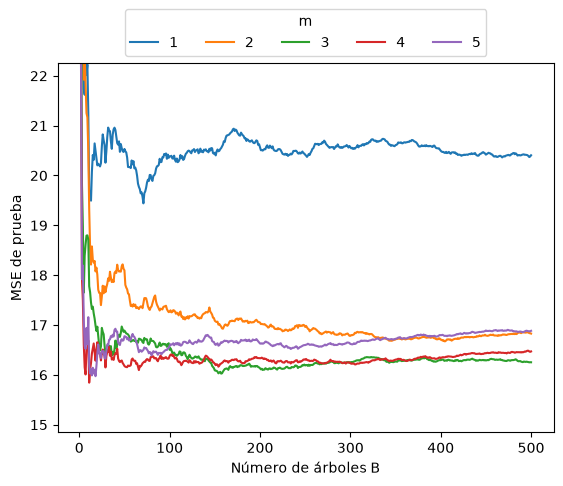

In [66]:
bosques = {m: clone(bosque).set_params(max_features = m, oob_score = True).fit(Xb_ent, yb_ent)
            for m in range (1, 6)}

mse_B = mse_por_arboles(bosques, Xb_pru, yb_pru)

In [69]:
errores_boston = errores_bosques(bosques, yb_ent, Xb_pru, yb_pru)
print(errores_boston)

     MSE_OOB  MSE_prueba
1  18.668576   20.405705
2  15.635333   16.828145
3  15.362894   16.252449
4  15.597605   16.469637
5  15.643364   16.883537


In [71]:
m_mejor = errores_boston["MSE_prueba"].idxmin()

imp_boston = tabla_importancia(bosques[m_mejor], Xb_pru, yb_pru)

print(imp_boston)

         impureza  permutacion
lstat    0.402709    52.407021
rm       0.440392    29.589283
crim     0.049731     4.505837
ptratio  0.061095     3.463531
dis      0.046072     3.163840


In [76]:
hitters = load_data("Hitters").dropna(subset = ["Salary"])
Xh = hitters[["CRuns", "CRBI", "CHits", "Years", "Walks", "PutOuts"]]
yh = np.log(hitters["Salary"])

In [77]:
Xh_ent, Xh_pru, yh_ent, yh_pru = train_test_split(Xh, yh, train_size = 200, shuffle = False)

/var/folders/t1/z9wpfgts6hg2hkzn2rwjw6q40000gn/T/ipykernel_70122/505916073.py:65: Pandas4Warning: The copy keyword is deprecated and will be removed in a future version. Copy-on-Write is active in pandas since 3.0 which utilizes a lazy copy mechanism that defers copies until necessary. Use .copy() to make an eager copy if necessary.
  ax = curvas.plot(logx=True, marker="o", xlabel=r"$\lambda$", ylabel="MSE")


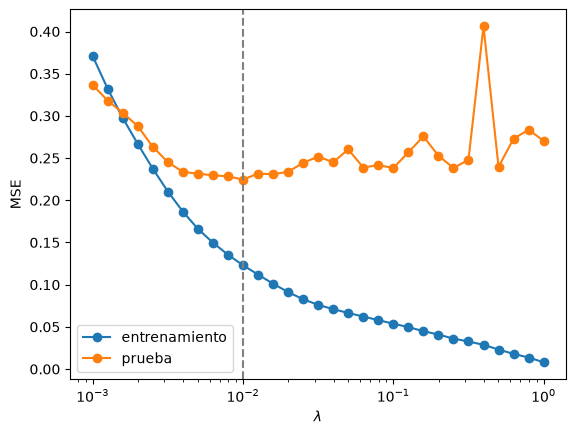

In [78]:
gb = GradientBoostingRegressor(n_estimators = 1000, max_leaf_nodes = 2, max_depth = None, random_state = SEMILLA)

lambdas = np.logspace(-3, 0, 31)
mse_lambda = curva_lambda(gb, Xh, yh, lambdas, n_entrenamiento = 200)

In [87]:
lam_mejor = mse_lambda["prueba"].idxmin()

In [88]:
gb.set_params(learning_rate = lam_mejor)
mse_hitters = comparar_modelos({"Boosting, d = 1":gb,
                                "Boosting, d = 4": clone(gb).set_params(max_leaf_nodes = 5),
                                "Regresion Lineal Multiple": LinearRegression(),
                                "Bosque aleatorio": clone(bosque)},
                                Xh_ent, yh_ent, Xh_pru, yh_pru)

In [89]:
print(mse_hitters)

                                MSE        R2
Boosting, d = 1            0.224478  0.651773
Boosting, d = 4            0.223192  0.653768
Regresion Lineal Multiple  0.450016  0.301901
Bosque aleatorio           0.279723  0.566073


In [92]:
bike = load_data("Bikeshare").astype({"hr":float})
X = bike[["hr", "workingday", "temp", "atemp", "hum", "windspeed"]]

X_ent, X_test, y_ent, y_test = train_test_split(X, bike[["bikers"]], test_size = 0.3, random_state = SEMILLA)

In [95]:
rf_bike = clone(bosque)

errores_bike = comparar_modelos({"Bosque aleatorio": rf_bike,
                                "Regresion Lineal Multiple": LinearRegression()},
                                X_ent, y_ent, X_pru, y_pru)

/Users/torodriguezt/entornos/estadistica-II/lib/python3.12/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


In [96]:
print(errores_bike)

                                    MSE        R2
Bosque aleatorio            3292.652663  0.807194
Regresion Lineal Multiple  10955.696457  0.358473


In [97]:
X_ruido = agregar_ruido(X)

rf_ruido = clone(bosque).fit(X_ruido.loc[X_ent.index], y_ent)
imp_ruido = tabla_importancia(rf_ruido, X_ruido.loc[X_pru.index], y_pru)

print(imp_ruido)

/Users/torodriguezt/entornos/estadistica-II/lib/python3.12/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


            impureza   permutacion
hr          0.506961  13431.640264
atemp       0.160824   2347.327558
workingday  0.027985   2155.303651
temp        0.139642   1973.591638
hum         0.090544   1578.774590
windspeed   0.031443    238.656291
ruido_cont  0.036777     14.598179
ruido_bin   0.005823    -19.142767


In [98]:
X["temp"].corr(X["atemp"])

np.float64(0.9920215399279333)

In [101]:
rf_sin_atemp = clone(bosque).fit(X_ent.drop(columns = "atemp"), y_ent)

imp_atemp = pd.DataFrame({
    "con_atemp": tabla_importancia(rf_bike, X_pru, y_pru)["permutacion"],
    "sin_atemp": tabla_importancia(rf_sin_atemp, X_pru.drop(columns = "atemp"), y_pru)["permutacion"]
})

print(imp_atemp)

/Users/torodriguezt/entornos/estadistica-II/lib/python3.12/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


               con_atemp     sin_atemp
atemp        2386.979458           NaN
hr          15756.713265  17644.820956
hum          1715.387891   1953.860841
temp         2028.368324   7469.164217
windspeed     237.317023    268.293969
workingday   2811.951103   3583.300969


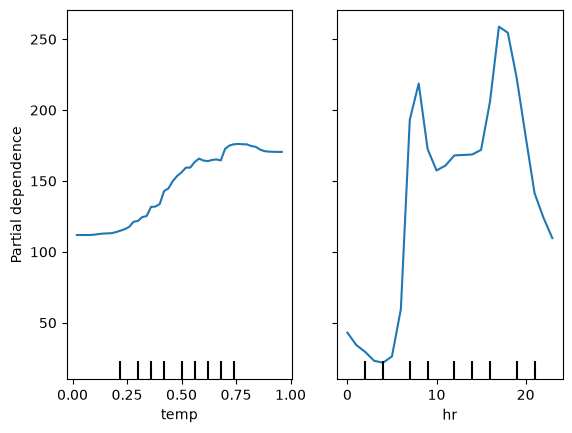

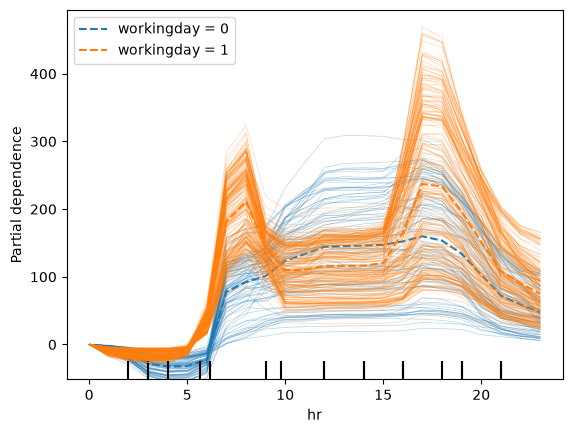

               0           1
0.0     0.000000    0.000000
1.0    -6.563209   -9.561633
2.0   -13.302854  -13.477861
3.0   -28.157958  -15.320287
4.0   -32.510113  -15.181218
5.0   -31.942376   -9.255043
6.0   -22.250212   33.692355
7.0    77.951396  181.383541
8.0    92.242948  211.520602
9.0   101.215401  142.458930
10.0  123.325487  109.851296
11.0  133.793542  110.161128
12.0  144.188575  116.185639
13.0  145.367426  116.062699
14.0  146.077437  116.334074
15.0  147.238900  120.420389
16.0  152.284055  165.325451
17.0  159.835099  237.086980
18.0  153.412903  233.611856
19.0  134.050781  196.093074
20.0  103.124478  151.326871
21.0   72.282656  108.881756
22.0   59.027097   90.291997
23.0   47.622069   74.997149


In [103]:
dp = graficar_dependencia_parcial(rf_bike, X_ent, ["temp", "hr"])
ice_hr = graficar_ice_por_grupo(rf_bike, X_ent, "hr", grupo = "workingday")

print(ice_hr)

In [107]:
sustituo = DecisionTreeRegressor(max_depth = 3, random_state = SEMILLA)
sustituto.fit(X_ent, rf_bike.predict(X_ent))
evaluacion_sustituto = evaluar_sustituto(sustituto, rf_bike, X_pru, y_pru)

print(evaluacion_sustituto)

|--- hr <= 6.50
|   |--- hr <= 5.50
|   |   |--- hr <= 1.50
|   |   |   |--- value: [33.86]
|   |   |--- hr >  1.50
|   |   |   |--- value: [17.45]
|   |--- hr >  5.50
|   |   |--- workingday <= 0.50
|   |   |   |--- value: [27.12]
|   |   |--- workingday >  0.50
|   |   |   |--- value: [65.20]
|--- hr >  6.50
|   |--- temp <= 0.47
|   |   |--- atemp <= 0.30
|   |   |   |--- value: [87.91]
|   |   |--- atemp >  0.30
|   |   |   |--- value: [153.05]
|   |--- temp >  0.47
|   |   |--- hr <= 20.50
|   |   |   |--- value: [262.80]
|   |   |--- hr >  20.50
|   |   |   |--- value: [155.74]

{'fidelidad': 0.7292294272137247, 'MSE_frente_a_Y': 8313.699591660295}
